# 01 — Exploratory Data Analysis

**Goal:** load CRMLS sold-listing data (≥ 6 months) and explore the distributions of the target `ClosePrice` and key features `LivingArea`, `BedroomsTotal`, `BathroomsTotalInteger`, and lot size.

**Scope (per task doc):** `PropertyType == "Residential"` and `PropertySubType == "SingleFamilyResidence"`.

Raw CSVs live in `Data/`, which is git-ignored. Outputs in this notebook are limited to aggregates and plots.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("Data")

## 1. Load data

Each file holds one month of closed listings (the first file covers all of 2022–2023). Only the columns needed for EDA are loaded to keep memory down.

In [2]:
COLS = [
    "ListingKey", "PropertyType", "PropertySubType", "CloseDate", "ClosePrice", "ListPrice",
    "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "LotSizeAcres",
    "YearBuilt", "DaysOnMarket", "CountyOrParish",
]

files = sorted(DATA_DIR.glob("CRMLSSold*.csv"))
raw = pd.concat(
    (pd.read_csv(f, usecols=COLS, low_memory=False).assign(source_file=f.name) for f in files),
    ignore_index=True,
)
raw["CloseDate"] = pd.to_datetime(raw["CloseDate"], errors="coerce")

print(f"Files loaded: {len(files)}")
print(f"Rows: {len(raw):,}")
print(f"CloseDate range: {raw['CloseDate'].min():%Y-%m-%d} to {raw['CloseDate'].max():%Y-%m-%d}")
print(f"Distinct close months: {raw['CloseDate'].dt.to_period('M').nunique()}")

Files loaded: 30
Rows: 794,271
CloseDate range: 2022-01-01 to 2026-05-31
Distinct close months: 53


In [3]:
assert raw["CloseDate"].dt.to_period("M").nunique() >= 6, "Need at least 6 months of data"

### Remove duplicate listings

A few listings appear in more than one monthly file; keep the most recent record.

In [4]:
before = len(raw)
raw = raw.sort_values("CloseDate").drop_duplicates("ListingKey", keep="last")
print(f"Dropped {before - len(raw):,} duplicate ListingKey rows -> {len(raw):,} rows")

Dropped 646 duplicate ListingKey rows -> 793,625 rows


## 2. Restrict to single-family residential

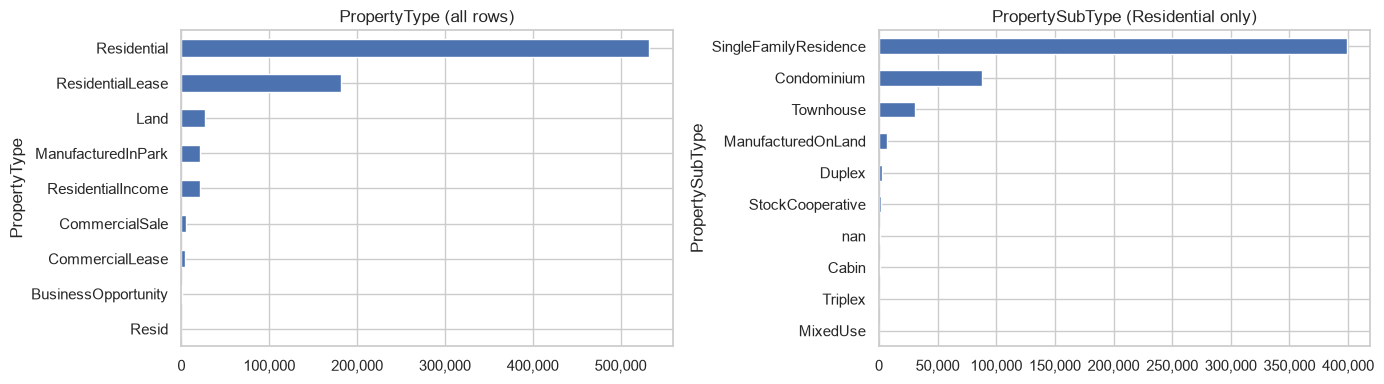

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
raw["PropertyType"].value_counts().plot.barh(ax=axes[0], title="PropertyType (all rows)")
(raw.loc[raw["PropertyType"] == "Residential", "PropertySubType"]
    .value_counts(dropna=False).head(10)
    .plot.barh(ax=axes[1], title="PropertySubType (Residential only)"))
for ax in axes:
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()

In [6]:
sfr = raw[(raw["PropertyType"] == "Residential")
          & (raw["PropertySubType"] == "SingleFamilyResidence")].copy()
print(f"Single-family residential rows: {len(sfr):,} ({len(sfr) / len(raw):.1%} of all rows)")

Single-family residential rows: 398,881 (50.3% of all rows)


## 3. Variables of interest

In [7]:
FEATURES = {
    "ClosePrice": "Close price ($)",
    "LivingArea": "Living area (sq ft)",
    "BedroomsTotal": "Bedrooms",
    "BathroomsTotalInteger": "Bathrooms",
    "LotSizeSquareFeet": "Lot size (sq ft)",
}

summary = sfr[list(FEATURES)].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
summary.insert(1, "missing", sfr[list(FEATURES)].isna().sum())
summary.insert(2, "pct_missing", sfr[list(FEATURES)].isna().mean() * 100)
summary.insert(3, "zeros", (sfr[list(FEATURES)] == 0).sum())
summary

,count,missing,pct_missing,zeros,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
ClosePrice,"398,880.00",1,0.00,1,"1,285,369.45","5,238,930.80",0.00,"235,000.00","365,000.00","620,000.00","889,000.00","1,425,000.00","3,150,000.00","6,200,000.00","989,500,000.00"
LivingArea,"398,671.00",210,0.05,158,"2,036.87","3,804.52",0.00,725.00,960.00,"1,373.00","1,800.00","2,418.00","3,801.00","5,655.30","2,308,680.00"
BedroomsTotal,"398,881.00",0,0.00,224,3.48,0.96,0.00,2.00,2.00,3.00,3.00,4.00,5.00,6.00,45.00
BathroomsTotalInteger,"398,806.00",75,0.02,167,2.61,1.18,0.00,1.00,1.00,2.00,2.00,3.00,5.00,6.00,175.00
LotSizeSquareFeet,"392,058.00",6823,1.71,215,"245,652.79","13,879,260.38",0.00,"1,800.00","3,249.00","5,663.00","7,246.00","10,340.00","49,466.60","258,310.80","2,087,220,960.00"


### Data-quality flags

Counts of values that are impossible or extreme and will need cleaning before modelling.

In [8]:
flags = pd.Series({
    "ClosePrice <= 0": (sfr["ClosePrice"] <= 0).sum(),
    "ClosePrice < $10k (likely rent / typo)": (sfr["ClosePrice"] < 10_000).sum(),
    "ClosePrice > $20M": (sfr["ClosePrice"] > 20_000_000).sum(),
    "LivingArea <= 0": (sfr["LivingArea"] <= 0).sum(),
    "LivingArea > 15,000 sq ft": (sfr["LivingArea"] > 15_000).sum(),
    "Bedrooms == 0": (sfr["BedroomsTotal"] == 0).sum(),
    "Bedrooms > 10": (sfr["BedroomsTotal"] > 10).sum(),
    "Bathrooms == 0": (sfr["BathroomsTotalInteger"] == 0).sum(),
    "Bathrooms > 10": (sfr["BathroomsTotalInteger"] > 10).sum(),
    "LotSize <= 0": (sfr["LotSizeSquareFeet"] <= 0).sum(),
    "LotSize > 10 acres": (sfr["LotSizeSquareFeet"] > 10 * 43_560).sum(),
}, name="rows").to_frame()
flags["pct"] = flags["rows"] / len(sfr) * 100
flags

,rows,pct
ClosePrice <= 0,1,0.00
ClosePrice < $10k (likely rent / typo),11,0.00
ClosePrice > $20M,275,0.07
LivingArea <= 0,158,0.04
"LivingArea > 15,000 sq ft",72,0.02
Bedrooms == 0,224,0.06
Bedrooms > 10,62,0.02
Bathrooms == 0,167,0.04
Bathrooms > 10,237,0.06
LotSize <= 0,215,0.05


## 4. ClosePrice (target)

Prices are heavily right-skewed, so they are shown on both a linear scale (clipped at the 99th percentile) and a log scale.

Skewness: raw = 138.35, log = 0.48


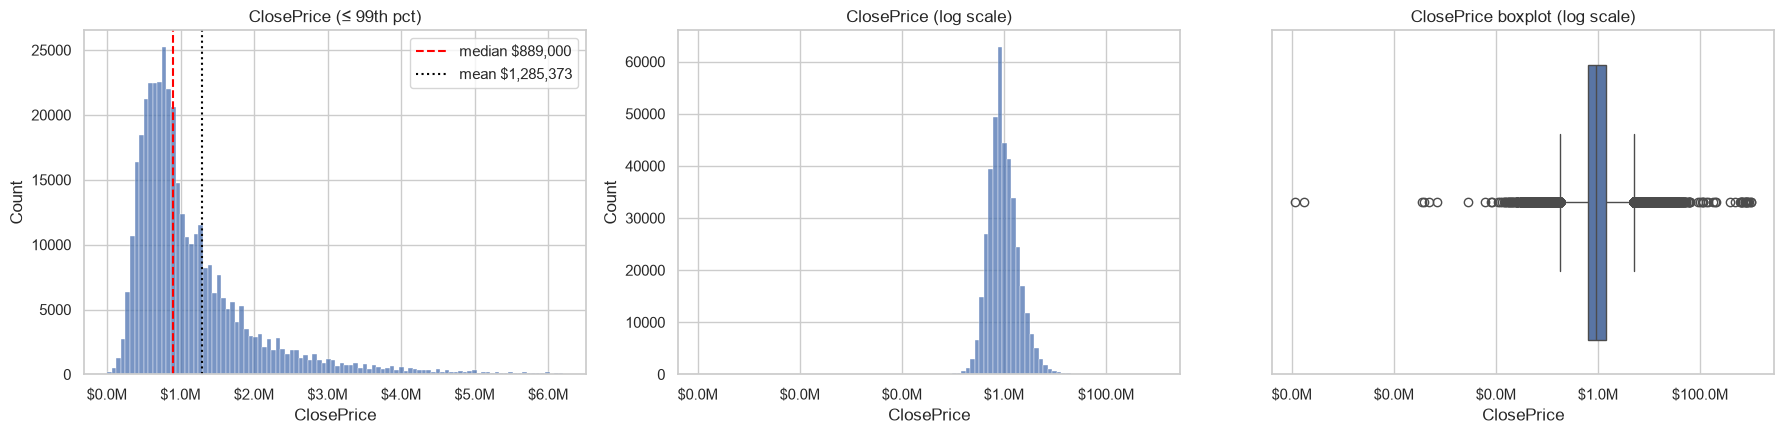

In [9]:
price = sfr.loc[sfr["ClosePrice"] > 0, "ClosePrice"]
p99 = price.quantile(0.99)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(price[price <= p99], bins=100, ax=axes[0])
axes[0].axvline(price.median(), color="red", ls="--", label=f"median ${price.median():,.0f}")
axes[0].axvline(price.mean(), color="black", ls=":", label=f"mean ${price.mean():,.0f}")
axes[0].set_title("ClosePrice (≤ 99th pct)")
axes[0].legend()

sns.histplot(price, bins=100, log_scale=True, ax=axes[1])
axes[1].set_title("ClosePrice (log scale)")

sns.boxplot(x=price, log_scale=True, ax=axes[2])
axes[2].set_title("ClosePrice boxplot (log scale)")

for ax in axes:
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x / 1e6:,.1f}M"))
plt.tight_layout()

print(f"Skewness: raw = {price.skew():.2f}, log = {np.log(price).skew():.2f}")

### ClosePrice over time

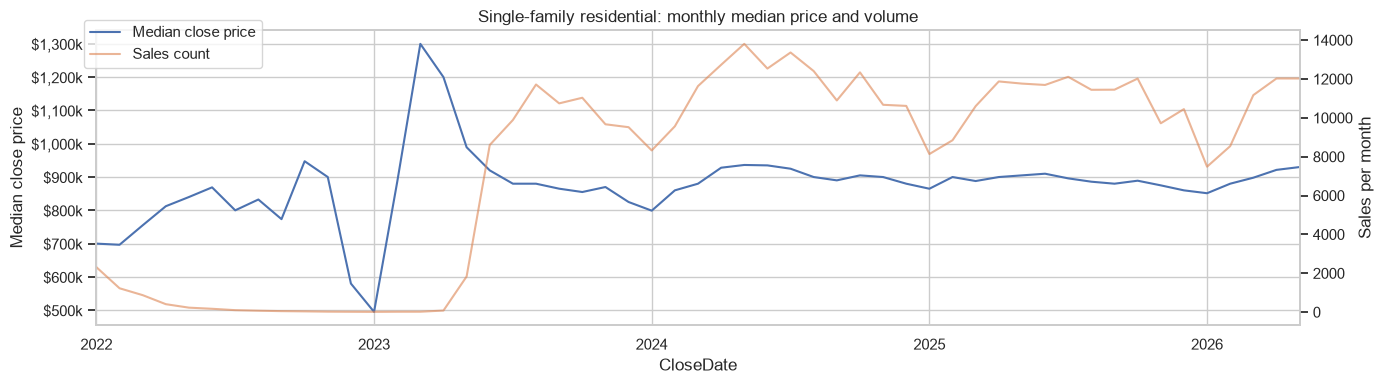

In [10]:
monthly = sfr.set_index("CloseDate").resample("MS")["ClosePrice"]
fig, ax1 = plt.subplots(figsize=(14, 4))
monthly.median().plot(ax=ax1, color="C0", label="Median close price")
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x / 1e3:,.0f}k"))
ax1.set_ylabel("Median close price")
ax2 = ax1.twinx()
monthly.size().plot(ax=ax2, color="C1", alpha=0.6, label="Sales count")
ax2.set_ylabel("Sales per month")
ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.06, 0.95))
ax1.set_title("Single-family residential: monthly median price and volume")
plt.tight_layout()

## 5. LivingArea

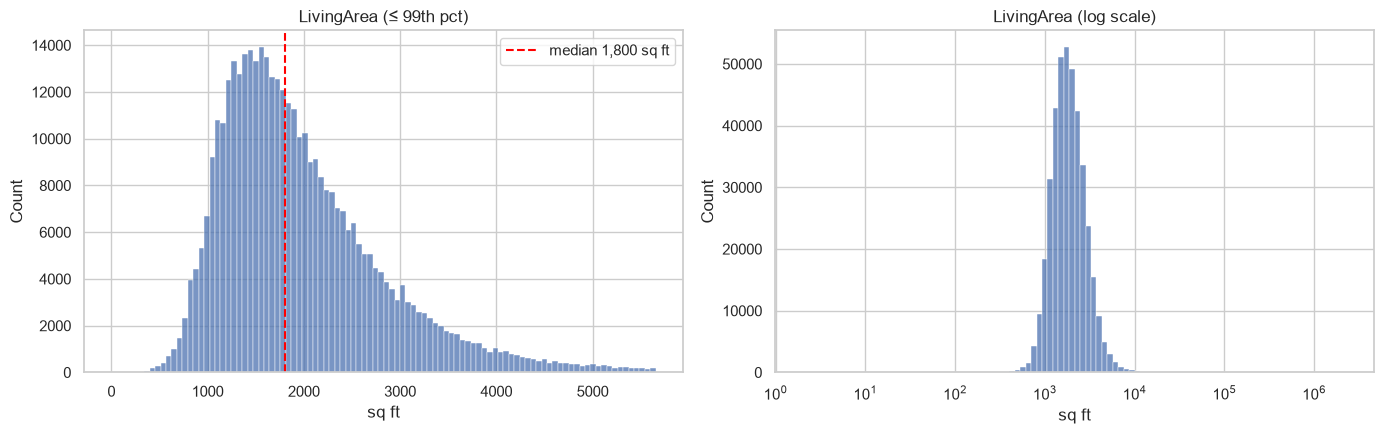

In [11]:
area = sfr.loc[sfr["LivingArea"] > 0, "LivingArea"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(area[area <= area.quantile(0.99)], bins=100, ax=axes[0])
axes[0].axvline(area.median(), color="red", ls="--", label=f"median {area.median():,.0f} sq ft")
axes[0].set_title("LivingArea (≤ 99th pct)")
axes[0].legend()
sns.histplot(area, bins=100, log_scale=True, ax=axes[1])
axes[1].set_title("LivingArea (log scale)")
for ax in axes:
    ax.set_xlabel("sq ft")
plt.tight_layout()

## 6. Bedrooms and Bathrooms

These are discrete, so bar charts of counts are used. Values above 8 are grouped as `8+`.

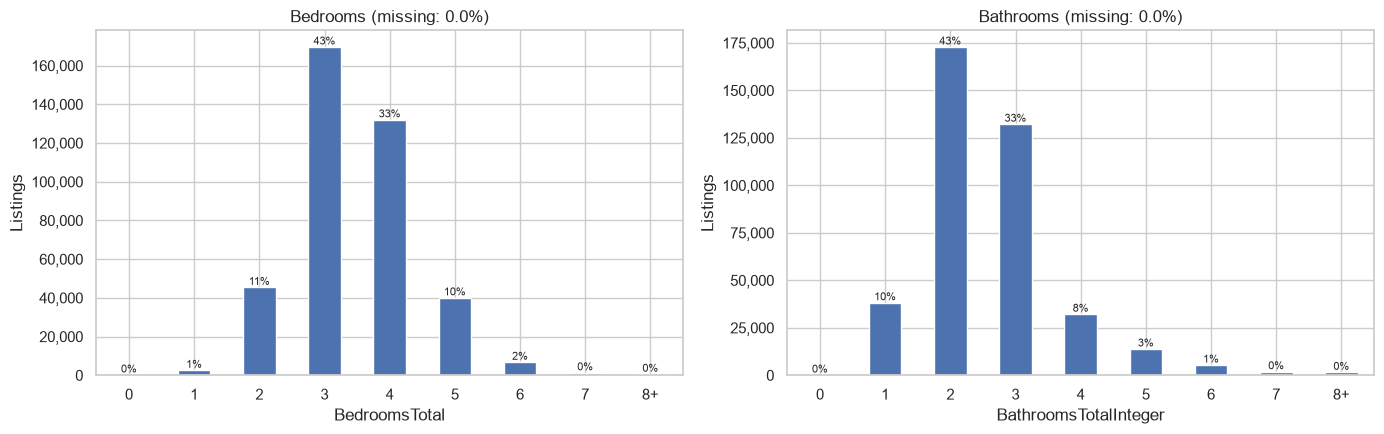

In [12]:
def capped_counts(s, cap=8):
    s = s.dropna().astype(int)
    labels = s.clip(upper=cap).astype(str).replace(str(cap), f"{cap}+")
    order = [str(i) for i in range(cap)] + [f"{cap}+"]
    return labels.value_counts().reindex(order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["BedroomsTotal", "BathroomsTotalInteger"]):
    counts = capped_counts(sfr[col])
    counts.plot.bar(ax=ax, rot=0)
    ax.set_title(f"{FEATURES[col]} (missing: {sfr[col].isna().mean():.1%})")
    ax.set_ylabel("Listings")
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    for p, v in zip(ax.patches, counts / counts.sum()):
        ax.annotate(f"{v:.0%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
plt.tight_layout()

## 7. Lot size

`LotSizeSquareFeet` is used (1 acre = 43,560 sq ft). Lot sizes have a very long tail (rural / acreage properties), so the log scale is the more useful view.

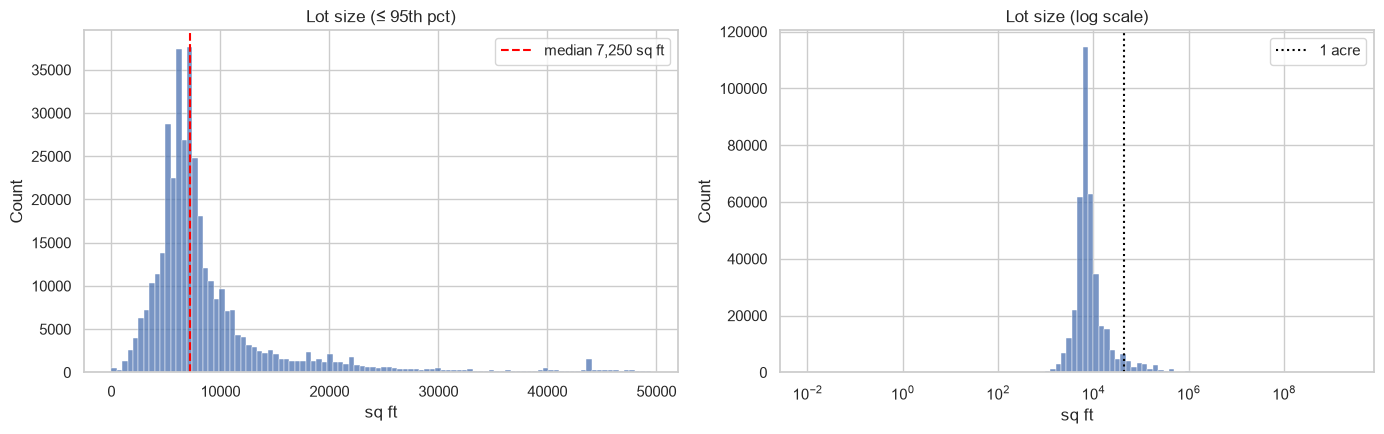

In [13]:
lot = sfr.loc[sfr["LotSizeSquareFeet"] > 0, "LotSizeSquareFeet"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(lot[lot <= lot.quantile(0.95)], bins=100, ax=axes[0])
axes[0].axvline(lot.median(), color="red", ls="--", label=f"median {lot.median():,.0f} sq ft")
axes[0].set_title("Lot size (≤ 95th pct)")
axes[0].legend()
sns.histplot(lot, bins=100, log_scale=True, ax=axes[1])
axes[1].axvline(43_560, color="black", ls=":", label="1 acre")
axes[1].set_title("Lot size (log scale)")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("sq ft")
plt.tight_layout()

## 8. Relationship with ClosePrice

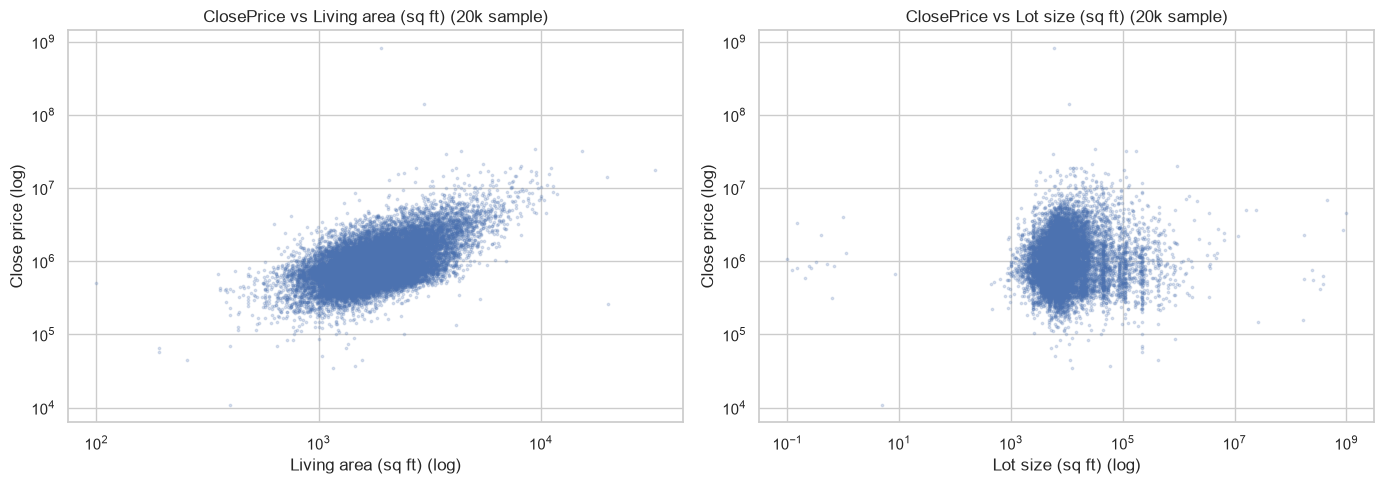

In [14]:
plot_df = sfr[(sfr["ClosePrice"] > 10_000) & (sfr["LivingArea"] > 0) & (sfr["LotSizeSquareFeet"] > 0)]
sample = plot_df.sample(min(20_000, len(plot_df)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["LivingArea", "LotSizeSquareFeet"]):
    ax.scatter(sample[col], sample["ClosePrice"], s=3, alpha=0.2)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(f"{FEATURES[col]} (log)")
    ax.set_ylabel("Close price (log)")
    ax.set_title(f"ClosePrice vs {FEATURES[col]} (20k sample)")
plt.tight_layout()

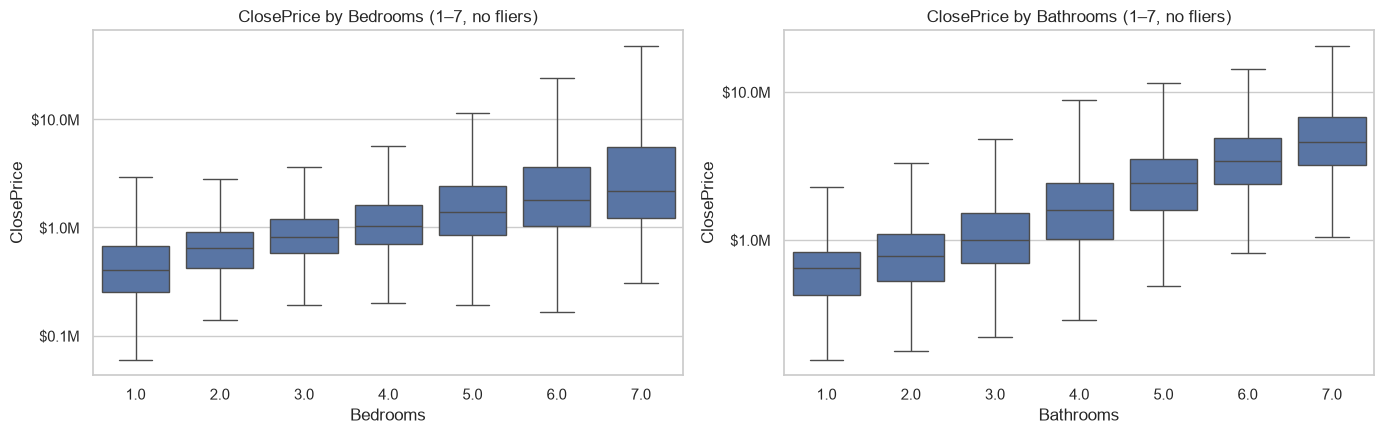

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["BedroomsTotal", "BathroomsTotalInteger"]):
    d = plot_df[plot_df[col].between(1, 7)]
    sns.boxplot(data=d, x=col, y="ClosePrice", log_scale=True, showfliers=False, ax=ax)
    ax.set_xlabel(FEATURES[col])
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x / 1e6:,.1f}M"))
    ax.set_title(f"ClosePrice by {FEATURES[col]} (1–7, no fliers)")
plt.tight_layout()

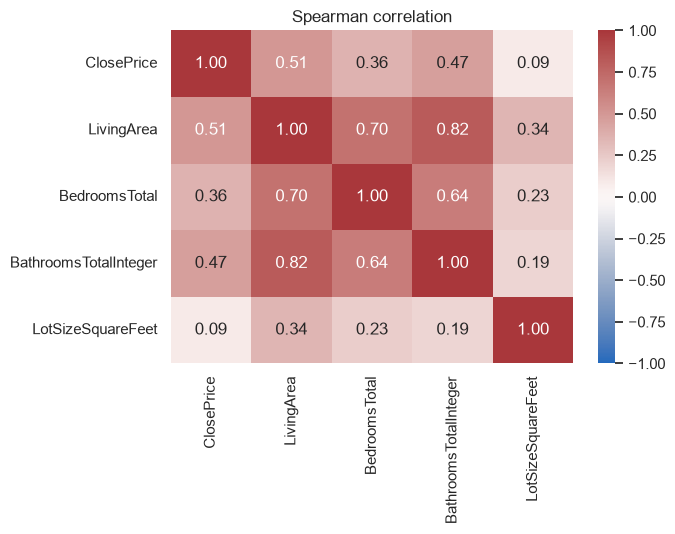

In [16]:
corr = plot_df[list(FEATURES)].corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation")
plt.tight_layout()

## 9. Takeaways

- **ClosePrice** is strongly right-skewed; a log transform makes it close to symmetric and is a sensible modelling target.
- **LivingArea** is the feature most correlated with price; bedrooms and bathrooms are also positively related but overlap heavily with living area.
- **Lot size** has an extreme long tail and only a weak relationship with price on its own; consider log-transforming and capping.
- Data-quality issues to address in cleaning: zero/near-zero prices, zero living area, zero bedrooms/bathrooms, and missing lot sizes (see section 3).